# Import and load json file

In [1]:
import pandas as pd
import json
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re

with open('../web_scraper/AIF 2025 Entrance Exam - April 7th_data.json') as f:
    data = json.load(f)

data

{'KUSHAL PAUDEL': {'email': 'salyani.kushal@gmail.com',
  'score': '70/100',
  'submitted_at': 'April 07 , 2025 08:07 PM',
  'plagiarism': 'High',
  'status': 'Passed',
  'submission_url': 'https://aishikshya.admin.fuseclassroom.com/exams/67ef8cd5a4725126dc01f785/submission/67f3cf237a982916b252d96c',
  'questions': [{'question_number': 1,
    'question_text': '1. 1. The orthogonal basis vectors  𝑖̂   and  𝑗̂   are transformed by  T  to a new set of orthogonal basis vectors  3𝑖̂ −2𝑗̂   and  4𝑖̂ +6𝑗̂, respectively. Find the transformation matrix  T.',
    'img_url': 'https://s3.amazonaws.com/fuseclassroom-resources-prod/quiz/image/60c84a9ac0f08d0098f132ce/1743752386776.png',
    'marks': '2 marks',
    'type': 'single',
    'selected_options': 'B',
    'options_metadata': '[{"label": "A", "value": "A00", "id": "A00", "selected": false}, {"label": "B", "value": "B01", "id": "B01", "selected": true}, {"label": "C", "value": "C02", "id": "C02", "selected": false}, {"label": "D", "value": "D

In [2]:
# Helper functions

def parse_score(score_str):
    """Convert '70/100' → (70, 100)."""
    try:
        obtained, total = score_str.split('/')
        return int(obtained), int(total)
    except Exception:
        return None, None

def parse_marks(marks_str):
    """Convert '2 marks' → 2."""
    try:
        return int(marks_str.split()[0])
    except Exception:
        return None

def parse_datetime(date_str):
    """Convert 'April 07 , 2025 08:07 PM' → datetime."""
    if not date_str:
        return None
    try:
        # remove unwanted spaces before commas
        cleaned = date_str.replace(" ,", ",").strip()
        return datetime.strptime(cleaned, "%B %d, %Y %I:%M %p")
    except Exception:
        return None


def parse_options_metadata(metadata_str):
    """
    Parse options_metadata JSON string safely.
    Returns a dict with:
      - all_options: list of option labels
      - correct_answers: list of labels where selected=True
    """
    try:
        opts = json.loads(metadata_str)

        if not isinstance(opts, list):
            return {"all_options": [], "correct_answers": []}

        all_options = [o.get("label") for o in opts if "label" in o]
        correct_answers = [o.get("label") for o in opts if o.get("selected")]

        return {
            "all_options": all_options,
            "correct_answers": correct_answers
        }
    except Exception:
        return {"all_options": [], "correct_answers": []}


# Create Dataframe

In [3]:
rows = []

for student_name, student_data in data.items():
    # Extract student-level fields
    email = student_data.get("email")
    score_str = student_data.get("score", "")
    obtained_score, total_score = parse_score(score_str)
    submitted_at = parse_datetime(student_data.get("submitted_at", ""))
    plagiarism = student_data.get("plagiarism")
    status = student_data.get("status")
    submission_url = student_data.get("submission_url")

    # Iterate over questions
    for q in student_data.get("questions", []):
        row = {
            "student_name": student_name,
            "email": email,
            "obtained_score": obtained_score,
            "total_score": total_score,
            "submitted_at": submitted_at,
            "plagiarism": plagiarism,
            "status": status,
            "submission_url": submission_url,
            "question_number": q.get("question_number"),
            "question_text": q.get("question_text"),
            "img_url": q.get("img_url"),
            "marks": parse_marks(q.get("marks", "")),
            "type": q.get("type"),
            "selected_options": q.get("selected_options"),
            "options_metadata": parse_options_metadata(q.get("options_metadata", "")),
            "is_correct": q.get("is_correct"),
        }
        rows.append(row)

In [4]:
# Create DataFrame
df = pd.DataFrame(rows)

In [5]:
print('number of students: ', df.shape[0]/50)

number of students:  495.0


# Feature Transformation

In [6]:
df.dtypes

student_name                object
email                       object
obtained_score               int64
total_score                  int64
submitted_at        datetime64[ns]
plagiarism                  object
status                      object
submission_url              object
question_number              int64
question_text               object
img_url                     object
marks                        int64
type                        object
selected_options            object
options_metadata            object
is_correct                    bool
dtype: object

In [7]:
df.isna().sum()

student_name            0
email                   0
obtained_score          0
total_score             0
submitted_at            0
plagiarism              0
status                  0
submission_url          0
question_number         0
question_text           0
img_url             20790
marks                   0
type                    0
selected_options        0
options_metadata        0
is_correct              0
dtype: int64

In [8]:
df[(df['student_name']=='ERIC RAI')& (df['question_number']==35)]['selected_options']

84    Select name, course_id from instructor natural...
Name: selected_options, dtype: object

In [9]:
df['options_metadata'].tolist()

[{'all_options': ['A', 'B', 'C', 'D'], 'correct_answers': ['B']},
 {'all_options': ['(a) The sensor network is perfectly calibrated.',
   '(b) Some sensor signals are linearly dependent.',
   '(c) The sensor network can capture all possible signals.',
   '(d) The sensor network is overdetermined.'],
  'correct_answers': ['(b) Some sensor signals are linearly dependent.']},
 {'all_options': ['a) The components have the same frequency.',
   'b) The components are linearly dependent.',
   'c) The components represent independent, non-overlapping sound sources.',
   'd) The components have the same amplitude.'],
  'correct_answers': ['c) The components represent independent, non-overlapping sound sources.']},
 {'all_options': ['Enhancing image resolution by selecting significant singular values',
   'Compressing the image by discarding less significant values.',
   'Detecting edges in the image through decomposition',
   'Rotating the image.'],
  'correct_answers': ['Compressing the image 

## Outlier Clipping

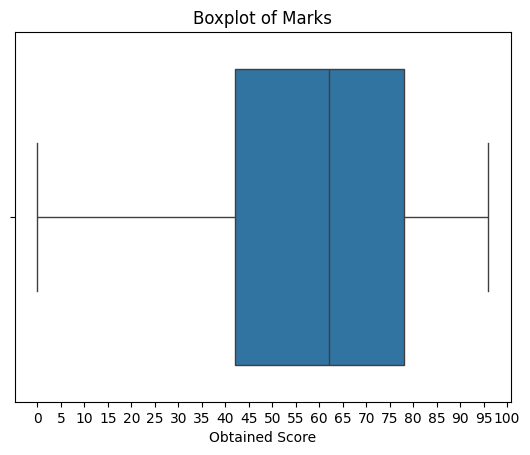

In [10]:
sns.boxplot(x=df['obtained_score'])

# Automatically set x-axis ticks from 0 to max score, with interval of 5
max_score = df['obtained_score'].max()
plt.xticks(np.arange(0, max_score + 5, 5))

plt.xlabel('Obtained Score')
plt.title('Boxplot of Marks')
plt.show()

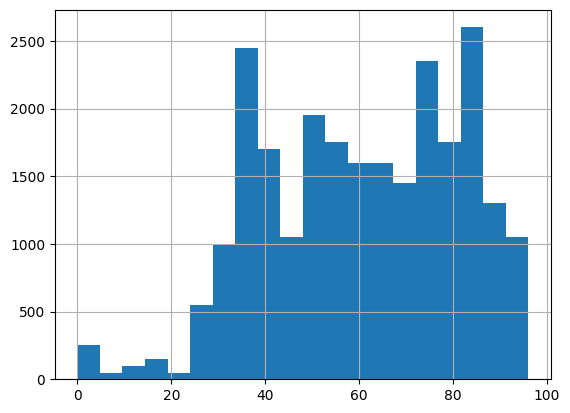

In [11]:
df['obtained_score'].hist(bins=20)
plt.show()


In [12]:
Q1 = df['obtained_score'].quantile(0.25)
Q3 = df['obtained_score'].quantile(0.75)
 
IQR = Q3 - Q1

print('lower quartile range: ',Q1 - 1.5 * IQR )
print('upper quartile range: ',Q3 + 1.5 * IQR )

# Outliers are values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
outliers = df[(df['obtained_score'] < (Q1 - 1.5 * IQR)) |
              (df['obtained_score'] > (Q3 + 1.5 * IQR))]

print(outliers)


lower quartile range:  -12.0
upper quartile range:  132.0
Empty DataFrame
Columns: [student_name, email, obtained_score, total_score, submitted_at, plagiarism, status, submission_url, question_number, question_text, img_url, marks, type, selected_options, options_metadata, is_correct]
Index: []


### Remove students with marks less than 10

In [13]:
df[df['obtained_score'] < 10][['student_name', 'obtained_score']].drop_duplicates()


,student_name,obtained_score
12750,ARIF DIN MIYA,4
16300,GARIMA ROKAHA,0
17250,PRASIDDHA SHARMA,2
17750,RAJIB MAINALI,2
19500,SANGAM RANABHAT,0
23050,AAKASH PRASAD SAH,6


In [14]:
df = df[df['obtained_score'] >= 10]


In [15]:
df['options_metadata']

0        {'all_options': ['A', 'B', 'C', 'D'], 'correct...
1        {'all_options': ['(a) The sensor network is pe...
2        {'all_options': ['a) The components have the s...
3        {'all_options': ['Enhancing image resolution b...
4        {'all_options': ['To find the exact line that ...
                               ...                        
24745    {'all_options': ['Stack', 'Queue', 'Heap', 'Pr...
24746    {'all_options': ['Density Plot', 'Bar Chart', ...
24747    {'all_options': ['(‘we’, ‘are’, ‘humans’)', '(...
24748    {'all_options': ['Linear regression.', 'Hypoth...
24749    {'all_options': ['Maximize the accuracy of lea...
Name: options_metadata, Length: 24450, dtype: object

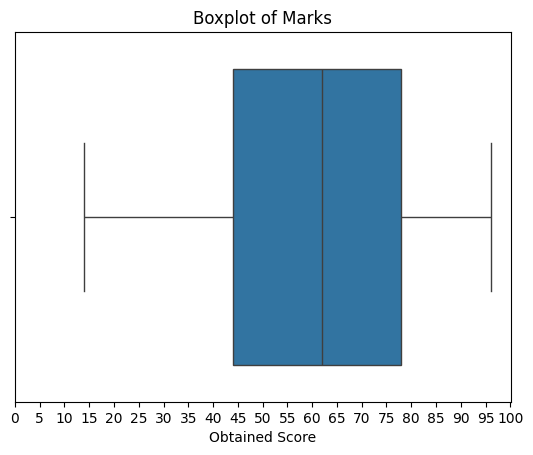

In [16]:
sns.boxplot(x=df['obtained_score'])

# Automatically set x-axis ticks from 0 to max score, with interval of 5
max_score = df['obtained_score'].max()
plt.xticks(np.arange(0, max_score + 5, 5))

plt.xlabel('Obtained Score')
plt.title('Boxplot of Marks')
plt.show()

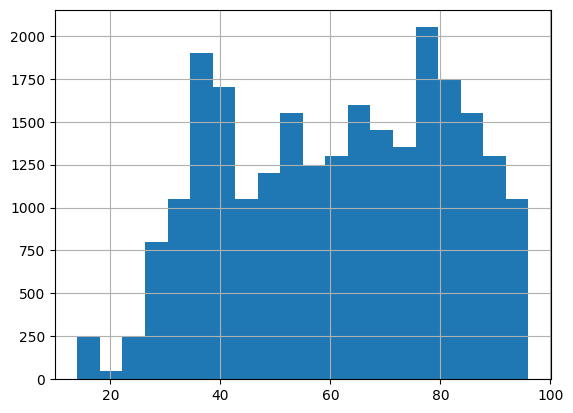

In [17]:
df['obtained_score'].hist(bins=20)
plt.show()


# Cleaning and transformation

In [18]:
# Step 1: Clean question_text
# --------------------
def clean_question_text(text):
    if pd.isna(text):
        return text
    # Remove leading question numbers like "1. 1. " or "49. 49."
    cleaned = re.sub(r'^\d+\.\s*\d+\.\s*', '', text)  
    cleaned = re.sub(r'^\d+\.\s*', '', cleaned)       # fallback: remove single number prefix
    return cleaned.strip()

df["clean_question_text"] = df["question_text"].apply(clean_question_text)


In [ ]:
df.to_csv('clean_text_question.csv')

In [23]:
df['clean_question_text'].drop_duplicates()

0     The orthogonal basis vectors  𝑖̂   and  𝑗̂   a...
1     A sensor network uses a matrix A to represent ...
2     An acoustic engineer is designing a noise-canc...
3     A digital image is represented as a matrix. Us...
4                                                      
6     A company's profit P (in dollars) from selling...
8     The rate of water flow into a tank is given by...
9     Suppose you have a 60% chance of passing this ...
10    A spam filter uses Bayes' Theorem to classify ...
11    You are tasked to create a statistical distrib...
12    A continuous random variable T has a uniform d...
13    For a standard normal distribution, what is th...
14    A large population has a mean weight of 150 lb...
15    If X and Y are uncorrelated variable then this...
16    A software company is running an A/B test to c...
17                What is the result of [1, 2, 3] + "4"
18    Given: a = [1,2,3,4,5,6]. Here, which of the f...
19    What is the output of the following code s

In [ ]:
# --------------------
# Step 2: Assign unique Question IDs
# --------------------
unique_questions = df[["clean_question_text", "img_url", "marks", "type"]].drop_duplicates().reset_index(drop=True)
unique_questions["question_id"] = ["Q" + str(i+1) for i in range(len(unique_questions))]

# Map back to df
df = df.merge(unique_questions, on=["clean_question_text", "img_url", "marks", "type"], how="left")


In [ ]:
len(df['clean_question_text'].tolist())/50

In [ ]:
# --------------------
# Step 3: Assign unique Student IDs
# --------------------
unique_students = df[["student_name", "email"]].drop_duplicates().reset_index(drop=True)
unique_students["student_id"] = ["S" + str(i+1) for i in range(len(unique_students))]

# Map back to df
df = df.merge(unique_students, on=["student_name", "email"], how="left")


In [ ]:
unique_questions.shape

In [ ]:
# --------------------
# Step 4: Split Questions (with vs without images)
# --------------------
questions_with_img = unique_questions[unique_questions["img_url"].notna()]
questions_without_img = unique_questions[unique_questions["img_url"].isna()]


In [ ]:
df

In [ ]:
# --------------------
# Final Normalized Tables (2NF ready)
# --------------------

# Student table
students_table = unique_students[["student_id", "student_name", "email"]]

# Question table
questions_table = unique_questions[["question_id", "clean_question_text", "img_url", "marks", "type"]]

# Submission table (relationship)
submissions_table = df[[
    "student_id", "question_id", "obtained_score", "total_score", 
    "submitted_at", "plagiarism", "status", "submission_url", 
    "selected_options", "options_metadata", "is_correct"
]]

In [ ]:
students_table

In [ ]:
questions_table.shape

In [ ]:
submissions_table.shape

In [ ]:
import json

# Ensure options_metadata is consistently serialized
df["options_metadata_str"] = df["options_metadata"].apply(
    lambda x: json.dumps(x, sort_keys=True) if isinstance(x, (list, dict)) else str(x)
)

# Group by question_id and count unique option sets
metadata_check = df.groupby("question_id")["options_metadata_str"].nunique()

# Find inconsistent questions (options differ across submissions)
inconsistent_questions = metadata_check[metadata_check > 1]

print("Questions with inconsistent options_metadata:")
print(inconsistent_questions)
